In [20]:
import numpy as np
import pandas as pd
from nltk.classify import NaiveBayesClassifier
from nltk.corpus import subjectivity
from nltk.sentiment import SentimentAnalyzer
from nltk.sentiment.util import *

import numpy as np 
import pandas as pd 
#pd.set_option('display.max_colwidth', -1)
from time import time
import re
import string
import os
from pprint import pprint
import collections

import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="darkgrid")
sns.set(font_scale=1.3)

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.metrics import classification_report

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
#from sklearn.externals import joblib
import joblib as jb

#import gensim

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

import warnings
warnings.filterwarnings('ignore')

np.random.seed(37)

In [21]:
# Reading the saved data pickle file
df  = pd.DataFrame()
df = pd.read_pickle('/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/data/pkl/pickled_filtered_lead_para_sp500_clean.pkl', compression=None)
df_sentiment=pd.read_pickle('/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/data/pkl/sentiment.pkl', compression=None)
df_vix_2010_2021=pd.read_csv('/Users/Farid Srouji/Documents/Research/master/globaldata/vix_2010_2021.csv')
df_options=pd.read_csv('/Users/Farid Srouji/Documents/Research/master/globaldata/vix_2010_2021.csv')

In [22]:
df["articles"].describe()
df = df.join(df_sentiment)
df["vix"] = df["adj close"]#.apply(np.int)
df["vix_ln_return"]=np.log(df["vix"]/df["vix"].shift(1))
df['sentiment'] = df[["sentiment"]].apply(pd.to_numeric)
df["sentiment_ewm"]=df["sentiment"].ewm(10).mean()
df["date"]=df.index
# df['date'] = pd.date_range(start='25/9/2019', periods=len(df), freq='D')
df_part1 = df.loc['2019-09-25':'2020-02-14']
df_part2 = df.loc['2020-02-15':'2020-05-31']
df_part3 = df.loc['2020-06-01':'2021-07-15']

In [23]:
df1_part3 = df_part3
idx = pd.date_range('2020-06-01', '2021-07-15')
df1_part3.index = pd.DatetimeIndex(df1_part3.index)

In [35]:
df_vix_2010_2021['Date']= pd.to_datetime(df_vix_2010_2021['Date'])
df_vix_2010_2021.index= df_vix_2010_2021['Date']
print("df_vix_2010_2021['Date']="+str(type(df_vix_2010_2021['Date'])))
print("df_part3['Date']="+str(type(df_part3['date'])))

df_vix_2010_2021['Date']=<class 'pandas.core.series.Series'>
df_part3['Date']=<class 'pandas.core.series.Series'>


In [30]:
df_vix_2010_2021["vix"] = df_vix_2010_2021["Adj Close"]#.apply(np.int)
df_vix_2010_2021["vix_ln_return"]=np.log(df_vix_2010_2021["vix"]/df_vix_2010_2021["vix"].shift(1))

In [37]:
import datetime as dt
from datetime import date
import calendar
my_date = date.today()
calendar.day_name[my_date.weekday()] 

# Prepare data
df_part3['year'] = [d.year for d in df_part3.index]
df_part3['month'] = [d.strftime('%b') for d in df_part3.index]
df_part3['day'] = [d for d in df_part3.index.day_name()]
years = df_part3['year'].unique()
df_part3['month-year'] = [d.strftime('%b') + str(d.year) for d in df_part3.index]

df_vix_2010_2021['year'] = [d.year for d in df_vix_2010_2021.Date]
df_vix_2010_2021['month'] = [d.strftime('%b') for d in df_vix_2010_2021.Date]
df_vix_2010_2021['day'] = [d for d in df_vix_2010_2021.index.day_name()]
years = df_vix_2010_2021['year'].unique()
df_vix_2010_2021['month-year'] = [d.strftime('%b') + str(d.year) for d in df_vix_2010_2021.Date]

<AxesSubplot:xlabel='year', ylabel='vix'>

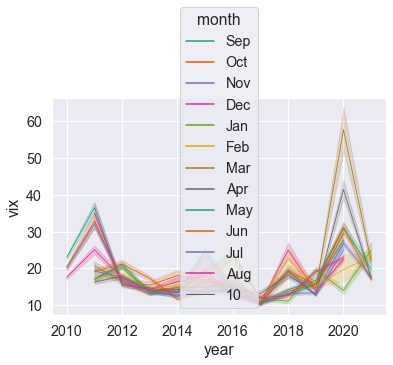

In [40]:
sns.lineplot(x="year", y="vix", data=df_vix_2010_2021, hue="month", palette="Dark2", size=30)

In [ ]:
# Split data into train data(including validation data) and test data
split_ratio = 0.8

# data = df_part3.set_index('day')
len_data = df_part3.shape[0]

train_org = df_part3.iloc[:int(len_data*split_ratio),]
test_org = df_part3.iloc[int(len_data*split_ratio):,]

print('train set',train_org.shape)
print('test set',test_org.shape)

In [ ]:
# start with simple scatterplot
sns.set(rc={"figure.figsize":(8, 4)})
sns.scatterplot(x='day',y='vix',data=df_part3)
#plt.show()      
# mean_by_dtexp = df_part3.groupby('day').mean()['vix']
plt.figure(figsize=(7,5))
plt.xlabel('day')
plt.ylabel('VIX')
# mean_by_dtexp_plot = mean_by_dtexp - 10  # for plotting purpose
# sns.barplot(x=mean_by_dtexp.index,y=mean_by_dtexp_plot.values,bottom=10, data=df_part3)
sns.barplot(x="day",y="vix", data=df_part3)

plt.show()

# len_by_dtexp = df_part3['day'].value_counts()
plt.figure(figsize=(7,5))
plt.xlabel('day')
plt.ylabel('Sentiment')
sns.barplot(x="day",y="sentiment", data=df_part3)
plt.show()

print('The amount of data seems to be insufficient when Day_till_expiration is high')

In [ ]:
sns.lineplot(x="month-year", y="vix", data=df_part3)
plt.figure(figsize=(7, 4))

plt.show()

sns.lineplot(x="month-year", y="sentiment", data=df_part3)
plt.figure(figsize=(7, 4))

plt.show()

In [ ]:
# plotting with confidence intervals 
sns.lineplot(x="year", y="Value", data=df)